# ONLINE SHOPPERS' PURCHASING INTENTION PREDICTION USING MACHINE LEARNING

## 1. Introduction

Online shopping has become an important part of modern business. Understanding customers' purchasing behaviour helps e-commerce businesses improve customer experience and increase sales.

This project focuses on predicting whether an online visitor will make a purchase based on their browsing behaviour and website interactions.

The project uses the Online Shoppers Purchasing Intention dataset and applies machine learning classification algorithms to predict purchasing intention.

## 2. Objectives

- To analyse online shoppers' browsing behaviour.
- To identify factors influencing purchasing decisions.
- To perform exploratory data analysis and visualize important patterns.
- To preprocess the dataset for machine learning.
- To build and compare different classification models.
- To identify the most influential features affecting purchasing predictions.

In [1]:
# Importing required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning libraries
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Machine learning algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

import warnings


In [2]:
df = pd.read_csv(r"C:\Users\nadhu\OneDrive\Desktop\online_shoppers_intention.csv")

df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


Dataset description and understanding

In [3]:

df.info()
df.describe()


<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType              12330 no

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType
count,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000
mean,2.315166,80.818611,0.503569,34.472398,31.731468,1194.746220,0.022191,0.043073,5.889258,0.061427,2.124006,2.357097,3.147364,4.069586
std,3.321784,176.779107,1.270156,140.749294,44.475503,1913.669288,0.048488,0.048597,18.568437,0.198917,0.911325,1.717277,2.401591,4.025169
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000
25%,0.000000,0.000000,0.000000,0.000000,7.000000,184.137500,0.000000,0.014286,0.000000,0.000000,2.000000,2.000000,1.000000,2.000000
50%,1.000000,7.500000,0.000000,0.000000,18.000000,598.936905,0.003112,0.025156,0.000000,0.000000,2.000000,2.000000,3.000000,2.000000
75%,4.000000,93.256250,0.000000,0.000000,38.000000,1464.157214,0.016813,0.050000,0.000000,0.000000,3.000000,2.000000,4.000000,4.000000
max,27.000000,3398.750000,24.000000,2549.375000,705.000000,63973.522230,0.200000,0.200000,361.763742,1.000000,8.000000,13.000000,9.000000,20.000000


### Dataset Overview

The dataset contains 12,330 records and 18 columns, including 17 independent variables and one dependent variable (Revenue).

The features describe different aspects of website visitor behaviour, such as administrative page visits, informational page visits, product-related page visits, browsing duration, visitor type, month and weekend activity.

The target variable, Revenue, indicates whether a visitor completed a purchase (True) or did not complete a purchase (False).

Checking missing values and duplicate records

In [4]:
df.isnull().sum()

Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64

In [5]:
df.duplicated().sum()

np.int64(125)

In [6]:
df = df.drop_duplicates()

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df['Revenue'].value_counts()

Revenue
False    10297
True      1908
Name: count, dtype: int64

### Data Quality Analysis

The dataset was checked for missing values and duplicate records.

No missing values were found in any of the columns. However, 125 duplicate records were identified and removed to avoid repeated observations.

After removing duplicates, the dataset contained 12,205 unique records.

The cleaned dataset was then used for further exploratory data analysis and model development.

Exploratory Data Analysis (EDA)

1) Purchase Intention Distribution

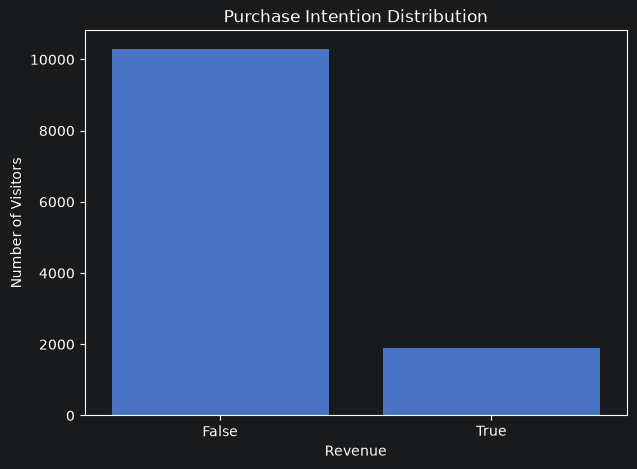

In [9]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='Revenue')

plt.title('Purchase Intention Distribution')
plt.xlabel('Revenue')
plt.ylabel('Number of Visitors')

plt.show()

Purchase Intention Distribution

The purchase intention distribution shows that out of 12,205 website visitors, 10,297 visitors (84.37%) did not make a purchase, whereas 1,908 visitors (15.63%) completed a purchase. This indicates that the dataset is imbalanced, with a significantly higher number of non-purchasing visitors. Therefore, appropriate evaluation metrics such as precision, recall, F1-score and ROC-AUC will be considered during model evaluation.
The dataset is imbalanced because the number of non-purchasing visitors is considerably higher than the number of purchasing visitors. Therefore, relying only on accuracy may not provide a complete picture of model performance.

2) Monthly visitor distribution

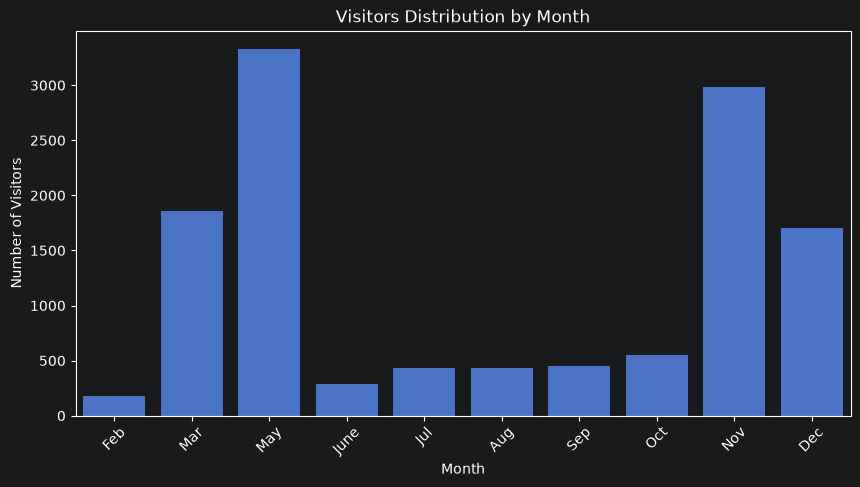

In [10]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x='Month',
    order=['Feb', 'Mar', 'May', 'June', 'Jul',
           'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
)

plt.title('Visitors Distribution by Month')
plt.xlabel('Month')
plt.ylabel('Number of Visitors')
plt.xticks(rotation=45)

plt.show()

Monthly Visitors Distribution

The monthly visitors distribution graph illustrates variations in website traffic across different months. May recorded the highest number of visitors, followed by November. March and December also experienced relatively high visitor traffic, whereas February recorded the lowest number of visitors. This analysis indicates that website traffic varies throughout the year, suggesting possible seasonal patterns in online shopping behaviour.

3) Purchase intention based on visitor type

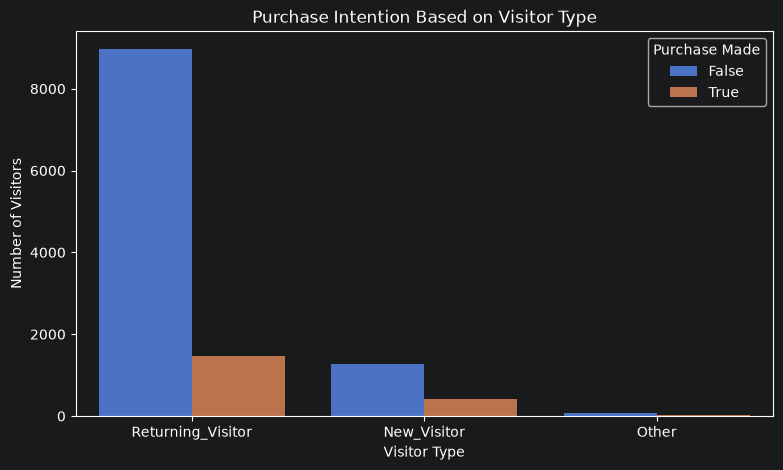

In [11]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x='VisitorType',
    hue='Revenue'
)

plt.title('Purchase Intention Based on Visitor Type')
plt.xlabel('Visitor Type')
plt.ylabel('Number of Visitors')
plt.legend(title='Purchase Made')

plt.show()

Purchase Intention Based on Visitor Type

The analysis shows that returning visitors account for the highest number of website visits and completed purchases. New visitors also contribute to online purchases, although their overall numbers are lower. The Other category represents a relatively small proportion of visitors. Across all visitor categories, non-purchasing visitors outnumber purchasing visitors. This suggests that visitor type is a useful feature to investigate when predicting online purchasing intention.

4) Weekend versus weekday purchasing behaviour

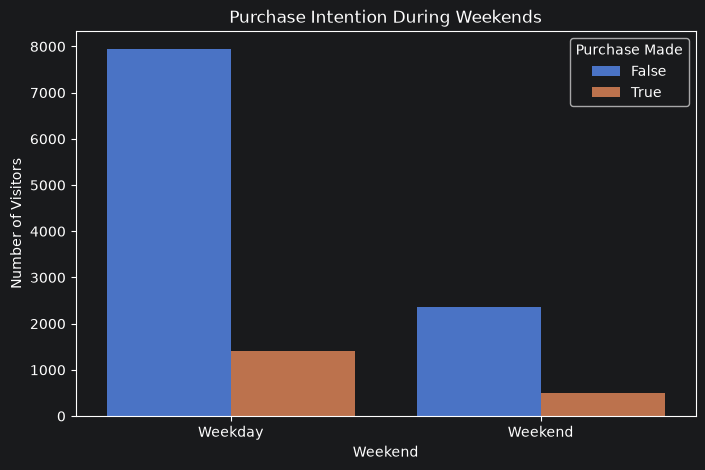

In [12]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='Weekend',
    hue='Revenue'
)

plt.title('Purchase Intention During Weekends')
plt.xlabel('Weekend')
plt.ylabel('Number of Visitors')

plt.xticks([0, 1], ['Weekday', 'Weekend'])

plt.legend(title='Purchase Made')

plt.show()

Purchase Intention During Weekends

The analysis compares online purchasing behaviour during weekdays and weekends. The graph indicates that weekdays have a higher number of website visitors and completed purchases compared with weekends. However, non-purchasing visitors outnumber purchasing visitors in both categories. This suggests that website traffic and purchasing activity vary depending on the day of the week. The Weekend feature can therefore be considered during machine learning model development.

5) Correlation heatmap analysis

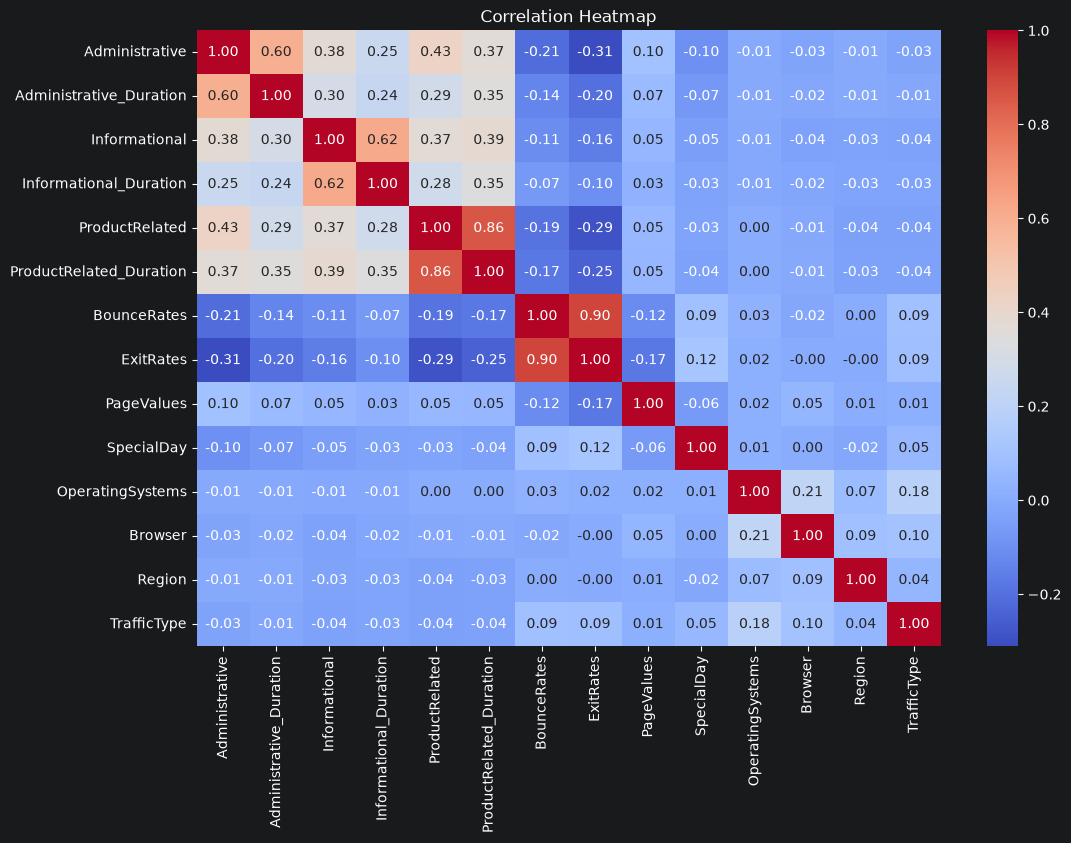

In [13]:
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(12, 8))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')

plt.show()

Correlation Heatmap Analysis

The correlation heatmap illustrates the relationships between numerical features in the online shoppers dataset. A strong positive correlation of 0.90 is observed between BounceRates and ExitRates. ProductRelated and ProductRelated_Duration also show a strong positive correlation of 0.86. Administrative and Administrative_Duration have a correlation of 0.60, while Informational and Informational_Duration have a correlation of 0.62. These findings indicate that certain website browsing features are closely related. The heatmap helps understand relationships among numerical variables and supports the feature analysis process.

In [14]:
# Independent variables
X = df.drop('Revenue', axis=1)

# Dependent variable
y = df['Revenue']

# Display independent variables
X.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True


In [15]:
# Display target variable
y.head()

0    False
1    False
2    False
3    False
4    False
Name: Revenue, dtype: bool

Train-test splitting

In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [17]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training data: (9764, 17)
Testing data: (2441, 17)
Training target: (9764,)
Testing target: (2441,)


Data preprocessing

In [18]:
# Identify numerical columns
numerical_cols = X.select_dtypes(include=np.number).columns.tolist()

# Identify categorical columns
categorical_cols = X.select_dtypes(
    include=['object', 'str', 'bool']
).columns.tolist()

print("Numerical columns:")
print(numerical_cols)

print("\nCategorical columns:")
print(categorical_cols)

Numerical columns:
['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']

Categorical columns:
['Month', 'VisitorType', 'Weekend']


Correct classification of columns

In [20]:
numerical_cols = [
    'Administrative',
    'Administrative_Duration',
    'Informational',
    'Informational_Duration',
    'ProductRelated',
    'ProductRelated_Duration',
    'BounceRates',
    'ExitRates',
    'PageValues',
    'SpecialDay'
]

Categorical columns

In [21]:
categorical_cols = [
    'Month',
    'OperatingSystems',
    'Browser',
    'Region',
    'TrafficType',
    'VisitorType',
    'Weekend'
]

Pre-processing pipeline

In [22]:

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing
preprocessor = ColumnTransformer(transformers=[
    ('num', numerical_transformer, numerical_cols),
    ('cat', categorical_transformer, categorical_cols)
])

### Data Preprocessing

Data preprocessing was performed to prepare the dataset for machine learning.

The features were divided into numerical and categorical variables.

Numerical features were processed using SimpleImputer with mean imputation and StandardScaler for feature scaling.

Categorical features were processed using SimpleImputer with most frequent imputation and OneHotEncoder to convert categorical values into numerical representations.

ColumnTransformer was used to combine both preprocessing operations, while Pipeline ensured that preprocessing and model training were performed consistently.

This preprocessing approach helps prepare the dataset for different machine learning algorithms.

Create four classification models

In [23]:

# Model 1: Logistic Regression
logistic_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        class_weight='balanced',
        max_iter=2000,
        random_state=42
    ))
])

# Model 2: Decision Tree
decision_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(
        class_weight='balanced',
        random_state=42
    ))
])

# Model 3: Random Forest
random_forest_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=200,
        class_weight='balanced',
        random_state=42
    ))
])

# Model 4: Gradient Boosting
gradient_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        random_state=42
    ))
])

print("All four models created successfully!")

All four models created successfully!


Train the models

In [24]:
# Train Logistic Regression
logistic_model.fit(X_train, y_train)

# Train Decision Tree
decision_model.fit(X_train, y_train)

# Train Random Forest
random_forest_model.fit(X_train, y_train)

# Train Gradient Boosting
gradient_model.fit(X_train, y_train)

print("All four models trained successfully!")

All four models trained successfully!


Make predictions

In [25]:
# Logistic Regression prediction
y_pred_logistic = logistic_model.predict(X_test)

# Decision Tree prediction
y_pred_decision = decision_model.predict(X_test)

# Random Forest prediction
y_pred_random = random_forest_model.predict(X_test)

# Gradient Boosting prediction
y_pred_gradient = gradient_model.predict(X_test)

In [ ]:
Check the predictions

In [26]:
print("Logistic Regression:", y_pred_logistic[:10])

print("Decision Tree:", y_pred_decision[:10])

print("Random Forest:", y_pred_random[:10])

print("Gradient Boosting:", y_pred_gradient[:10])

Logistic Regression: [False False False False False  True False False False False]
Decision Tree: [False False False False False  True False False False False]
Random Forest: [False False False False False  True False False False False]
Gradient Boosting: [False False False False False  True False False False False]


Model evaluation

In [27]:
models = {
    'Logistic Regression': logistic_model,
    'Decision Tree': decision_model,
    'Random Forest': random_forest_model,
    'Gradient Boosting': gradient_model
}

results = []

for name, model in models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1 Score': f1_score(y_test, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)

print(results_df.round(3))

                 Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
0  Logistic Regression     0.846      0.505   0.796     0.618    0.910
1        Decision Tree     0.854      0.537   0.497     0.516    0.709
2        Random Forest     0.896      0.653   0.715     0.682    0.925
3    Gradient Boosting     0.902      0.711   0.636     0.671    0.936


### Model Evaluation and Comparison

The four classification algorithms were evaluated using Accuracy, Precision, Recall, F1-score and ROC-AUC.

The results show that Gradient Boosting achieved the highest accuracy of 90.2%, indicating that it correctly classified the largest proportion of testing observations. It also achieved the highest precision of 71.1% and ROC-AUC of 93.6%.

Random Forest achieved the highest F1-score of 68.2%, demonstrating a better balance between precision and recall compared with the other models.

Logistic Regression achieved the highest recall of 79.6%, indicating that it identified the largest proportion of actual purchasing visitors.

Decision Tree showed comparatively weaker performance, with an F1-score of 51.6% and ROC-AUC of 70.9%.

Overall, Gradient Boosting demonstrated the strongest performance in terms of accuracy, precision and ROC-AUC, while Random Forest achieved the best F1-score.

Therefore, Gradient Boosting can be considered the strongest model based on overall predictive performance, while Random Forest provides a competitive balance between precision and recall.

Confusion matrix

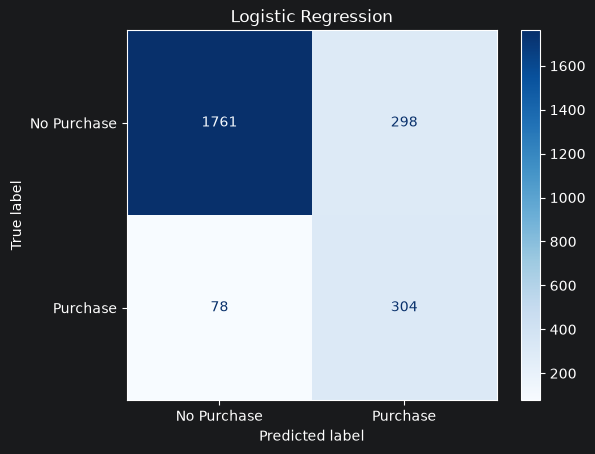

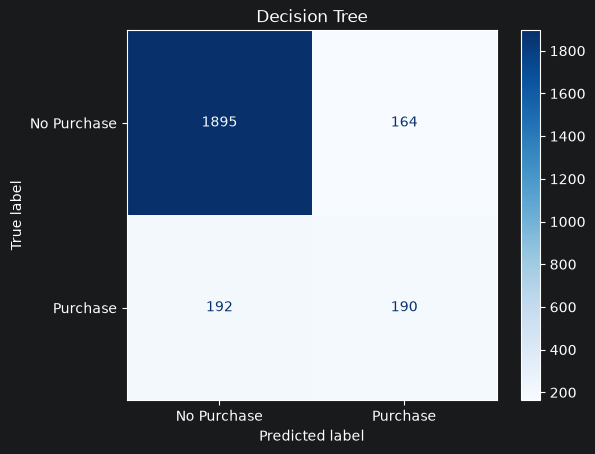

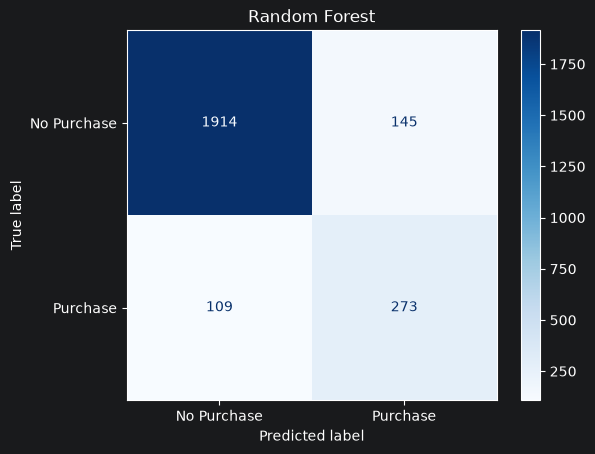

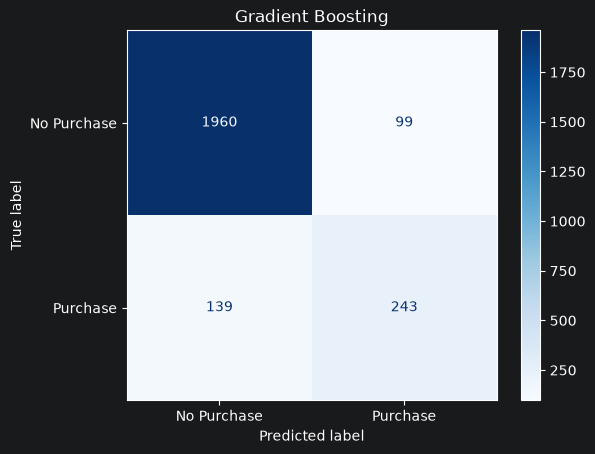

In [28]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

for name, model in models.items():
    y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=['No Purchase', 'Purchase']
    )

    disp.plot(cmap='Blues')
    plt.title(name)
    plt.show()

### Confusion Matrix Analysis

Confusion matrices were generated to examine the classification performance of all four machine learning models.

The confusion matrix provides four important outcomes:

- True Positive (TP): Actual purchasing visitors correctly predicted as purchasers.
- True Negative (TN): Actual non-purchasing visitors correctly predicted as non-purchasers.
- False Positive (FP): Non-purchasing visitors incorrectly predicted as purchasers.
- False Negative (FN): Purchasing visitors incorrectly predicted as non-purchasers.

Logistic Regression correctly identified the highest number of actual purchasing visitors among the four models.

Gradient Boosting correctly classified the highest number of non-purchasing visitors.

These results highlight the differences in how the models identify purchasing and non-purchasing visitors.

Therefore, confusion matrices provide additional information beyond overall accuracy and help understand the strengths and weaknesses of each classification model.

Feature importance

In [29]:
# Get feature names after preprocessing
feature_names = random_forest_model.named_steps['preprocessor'].get_feature_names_out()

# Get feature importance
importance = random_forest_model.named_steps['classifier'].feature_importances_

# Create a dataframe
feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importance
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by='Importance', ascending=False
)

print(feature_importance.head(10))

                         Feature  Importance
8                num__PageValues    0.317535
7                 num__ExitRates    0.097647
5   num__ProductRelated_Duration    0.082051
4            num__ProductRelated    0.067555
6               num__BounceRates    0.051917
1   num__Administrative_Duration    0.049086
0            num__Administrative    0.041721
17                cat__Month_Nov    0.025230
3    num__Informational_Duration    0.021263
2             num__Informational    0.015488


Feature Importance Analysis

Feature importance analysis was performed using the Random Forest classifier to identify the most influential variables in predicting online shoppers' purchasing intention.

The results show that PageValues is the most important feature, with an importance score of approximately 0.318. ExitRates is the second most important feature, followed by ProductRelated_Duration and ProductRelated.

This indicates that visitor browsing behaviour, time spent on product-related pages and page values play important roles in the model's purchasing predictions.

Therefore, understanding visitors' browsing patterns can help businesses better understand online shopping behaviour.

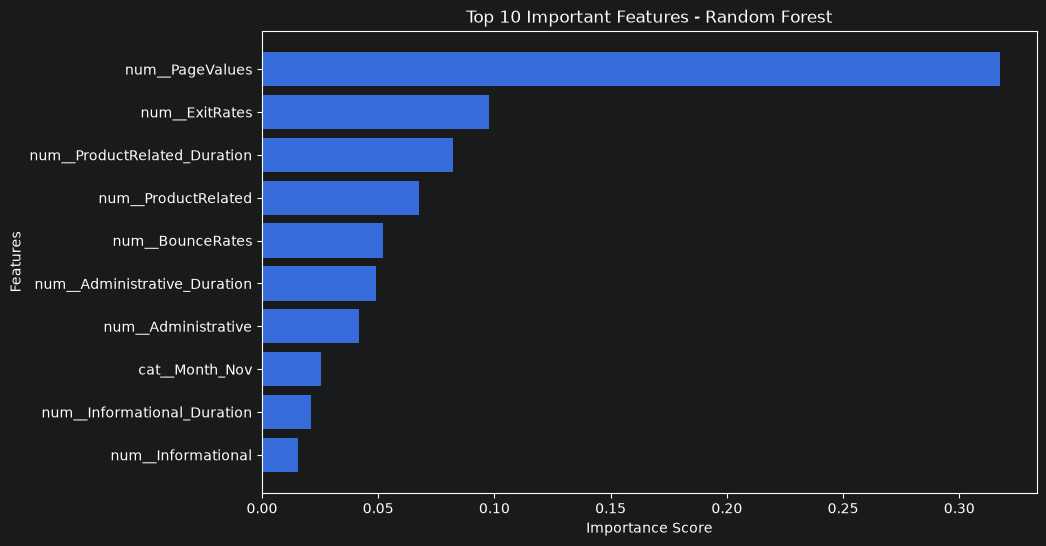

In [30]:
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance.head(10)['Feature'],
    feature_importance.head(10)['Importance']
)

plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.title('Top 10 Important Features - Random Forest')
plt.gca().invert_yaxis()
plt.show()

#  Conclusion

This project focused on predicting online shoppers' purchasing intention using machine learning classification algorithms.

The Online Shoppers Purchasing Intention dataset was explored, cleaned and preprocessed before developing four classification models: Logistic Regression, Decision Tree, Random Forest and Gradient Boosting.

Exploratory Data Analysis revealed that approximately 84.37% of visitors did not make a purchase, while 15.63% completed a purchase, indicating an imbalanced target distribution.

The models were evaluated using Accuracy, Precision, Recall, F1-score and ROC-AUC.

Among the four models, Gradient Boosting achieved the highest accuracy of 90.2% and ROC-AUC of 93.6%. Random Forest achieved the highest F1-score of 68.2%, while Logistic Regression achieved the highest recall of 79.6%.

Feature importance analysis using Random Forest identified PageValues as the most influential feature, followed by ExitRates, ProductRelated_Duration and ProductRelated.

Overall, this project demonstrates how machine learning techniques can be applied to analyse online shoppers' browsing behaviour and predict their purchasing intention.

The findings can help e-commerce businesses better understand visitor behaviour and develop strategies to improve customer engagement and purchasing conversions.